# Assignment no 5

## EXPLORATORY DATA ANALYSIS ON A DATASET


Objective:

The main goal of this assignment is to conduct a thorough exploratory analysis of the "cardiographic.csv" dataset to uncover insights, identify patterns, and understand the dataset's underlying structure. You will use statistical summaries, visualizations, and data manipulation techniques to explore the dataset comprehensively.

Dataset:

1.	LB - Likely stands for "Baseline Fetal Heart Rate (FHR)" which represents the average fetal heart rate over a period.
2.	AC - Could represent "Accelerations" in the FHR. Accelerations are usually a sign of fetal well-being.
3.	FM - May indicate "Fetal Movements" detected by the monitor.
4.	UC - Likely denotes "Uterine Contractions", which can impact the FHR pattern.
5.	DL - Could stand for "Decelerations Late" with respect to uterine contractions, which can be a sign of fetal distress.
6.	DS - May represent "Decelerations Short" or decelerations of brief duration.
7.	DP - Could indicate "Decelerations Prolonged", or long-lasting decelerations.
8.	ASTV - Might refer to "Percentage of Time with Abnormal Short Term Variability" in the FHR.
9.	MSTV - Likely stands for "Mean Value of Short Term Variability" in the FHR.
10.	ALTV - Could represent "Percentage of Time with Abnormal Long Term Variability" in the FHR.
11.	MLTV - Might indicate "Mean Value of Long Term Variability" in the FHR.


Tools and Libraries:

●	Python programming language
●	Data manipulation libraries 
●	Data visualization libraries (Matplotlib and Seaborn in Python)
●	Jupyter Notebook for documenting your analysis


Tasks:

1.	Data Cleaning and Preparation:
●	Load the dataset into a data frame or equivalent data structure.
●	Handle missing values appropriately (e.g., imputation, deletion).
●	Identify and correct any inconsistencies in data types (e.g., numerical values stored as strings).
●	Detect and treat outliers if necessary.

2.	Statistical Summary:
●	Provide a statistical summary for each variable in the dataset, including measures of central tendency (mean, median) and dispersion (standard deviation, interquartile range).
●	Highlight any interesting findings from this summary.

3.	Data Visualization:
●	Create histograms or boxplots to visualize the distributions of various numerical variables.
●	Use bar charts or pie charts to display the frequency of categories for categorical variables.
●	Generate scatter plots or correlation heatmaps to explore relationships between pairs of variables.
●	Employ advanced visualization techniques like pair plots, or violin plots for deeper insights.

4.	Pattern Recognition and Insights:
●	Identify any correlations between variables and discuss their potential implications.
●	Look for trends or patterns over time if temporal data is available.

5.	Conclusion:
●	Summarize the key insights and patterns discovered through your exploratory analysis.
●	Discuss how these findings could impact decision-making or further analyses.
Deliverables:
●	A detailed Jupyter Notebook file containing the code, visualizations, and explanations for each step of your analysis.
●	A brief report summarizing your findings, insights, and any recommendations for further analysis or actions based on the data.


1. Data Cleaning and Preparation


1.1 Load & inspect structure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("Cardiotocographic.csv")
print(df.shape)
df.head()

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

(2126, 14)

Dataset shape: (2126, 14)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2105 non-null   float64
 1   AC        2106 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2105 non-null   float64
 6   DP        2105 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2105 non-null   float64
 11  Width     2105 non-null   float64
 12  Tendency  2105 non-null   float64
 13  NSP       2105 non-null   float64
dtypes: float64(14)
memory usage: 232.7 KB

Missing values:
LB          21
AC          20
FM           0
UC           0
DL           0
DS          21
DP          21
ASTV         0
MSTV         0
ALTV         0

1. Data Cleaning and Preparation

1.1 Load & inspect structure

In [2]:

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Identify structurally incomplete rows
missing_per_row = df.isnull().sum(axis=1)

print("\nRows containing missing values:", (missing_per_row > 0).sum())
print("Rows with 6 or more missing values:", (missing_per_row >= 6).sum())

# Drop rows missing more than 3 values
df = df.dropna(thresh=len(df.columns) - 3).reset_index(drop=True)

# Fill remaining numeric missing values with column medians
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nShape after cleaning:", df.shape)


Rows containing missing values: 21
Rows with 6 or more missing values: 21

Missing values after cleaning:
LB          0
AC          0
FM          0
UC          0
DL          0
DS          0
DP          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
Width       0
Tendency    0
NSP         0
dtype: int64

Shape after cleaning: (2103, 14)


1.2 Handle missing values

In [3]:
# How many rows have >50% missing?
partial_rows = df.isnull().sum(axis=1)
print("Rows with any NaN:", (partial_rows > 0).sum())
print("Rows with >=6 NaNs:", (partial_rows >= 6).sum())

# Drop the structurally broken rows entirely
df = df.dropna(thresh=len(df.columns) - 3).reset_index(drop=True)

# Impute remaining NaNs with the median (robust to skew)
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print(df.isnull().sum().sum(), "NaNs remaining")

Rows with any NaN: 0
Rows with >=6 NaNs: 0
0 NaNs remaining


1.3 Correct data types & invalid values

In [4]:
# --- Show the offenders before fixing ---
print("ASTV < 0 :", (df["ASTV"] < 0).sum())      # e.g. -63, appears twice
print("ASTV > 100:", (df["ASTV"] > 100).sum())
print("MLTV < 0 :", (df["MLTV"] < 0).sum())      # e.g. -50.7
print("Width < 0:", (df["Width"] < 0).sum())     # e.g. -174
print("Width > 200:", (df["Width"] > 200).sum()) # e.g. 357
print("MSTV < 0:", (df["MSTV"] < 0).sum())       # e.g. -6.6
print("NSP not in {1,2,3}:", (~df["NSP"].isin([1,2,3])).sum())
print("Tendency not in {-1,0,1}:", (~df["Tendency"].isin([-1,0,1])).sum())

# 1. Bounded percentages: clip to [0, 100]
for c in ["ASTV", "ALTV"]:
    df[c] = df[c].clip(lower=0, upper=100)

# 2. Non-negative physiological quantities: clip at 0
for c in ["MSTV", "MLTV"]:
    df[c] = df[c].clip(lower=0)

# 3. Width: 0–200 is the physiological window
df["Width"] = df["Width"].clip(lower=0, upper=200)

# 4. Tendency: round the decimal noise back to its 3 categories
df["Tendency"] = df["Tendency"].round().clip(-1, 1).astype(int)

# 5. NSP: round to the nearest class, clip to {1,2,3}, cast to int
df["NSP"] = df["NSP"].round().clip(1, 3).astype(int)

# 6. Sanity check
print(df[["ASTV","MLTV","Width","MSTV","Tendency","NSP"]].agg(["min","max"]))


skewed = ["AC","FM","UC","DL","DS","DP","Width","MLTV"]
df_log = df.copy()
df_log[skewed] = np.log1p(df_log[skewed])

ASTV < 0 : 5
ASTV > 100: 5
MLTV < 0 : 11
Width < 0: 5
Width > 200: 5
MSTV < 0: 3
NSP not in {1,2,3}: 115
Tendency not in {-1,0,1}: 115
       ASTV    MLTV   Width   MSTV  Tendency  NSP
min   0.000   0.000   0.000  0.000        -1    1
max 100.000 101.400 200.000 13.800         1    3


2. Statistical Summary

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

summary = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Standard Deviation": df[numeric_cols].std(),
    "Variance": df[numeric_cols].var(),
    "Minimum": df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75),
    "IQR": (
        df[numeric_cols].quantile(0.75)
        - df[numeric_cols].quantile(0.25)
    ),
    "Maximum": df[numeric_cols].max(),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurt()
}).round(3)

print("\nStatistical summary:")
print(summary)

print("\nGeneral descriptive statistics:")
print(df.describe().T)

summary.to_csv("cardiotocographic_statistical_summary.csv")


Statistical summary:
            Mean  Median    Mode  Standard Deviation  Variance  Minimum  \
LB       133.342 133.000 133.000              11.268   126.974   51.842   
AC         0.003   0.002   0.000               0.004     0.000   -0.019   
FM         0.010   0.000   0.000               0.068     0.005   -0.481   
UC         0.004   0.004   0.000               0.003     0.000   -0.015   
DL         0.002   0.000   0.000               0.003     0.000   -0.015   
DS         0.000   0.000   0.000               0.000     0.000   -0.001   
DP         0.000   0.000   0.000               0.001     0.000   -0.005   
ASTV      47.016  49.000  65.000              17.518   306.875    0.000   
MSTV       1.370   1.200   0.800               1.136     1.289    0.000   
ALTV      10.227   0.000   0.000              19.165   367.313    0.000   
MLTV       8.402   7.400   0.000               7.233    52.317    0.000   
Width     70.501  67.486  39.000              39.473 1,558.096    0.000   
Ten

3. Data Visualization

3.1 Histograms — distribution shapes


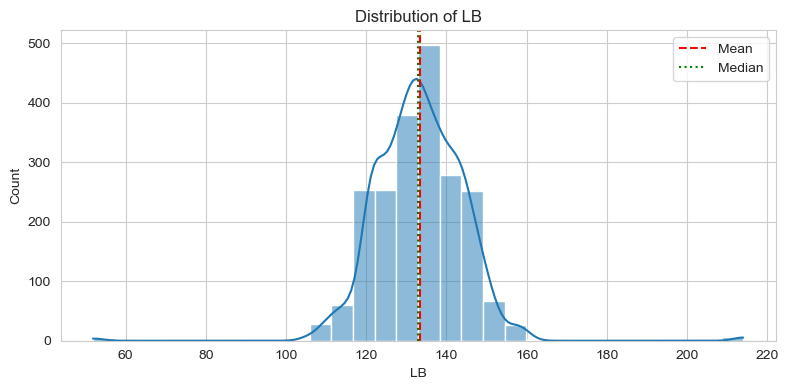

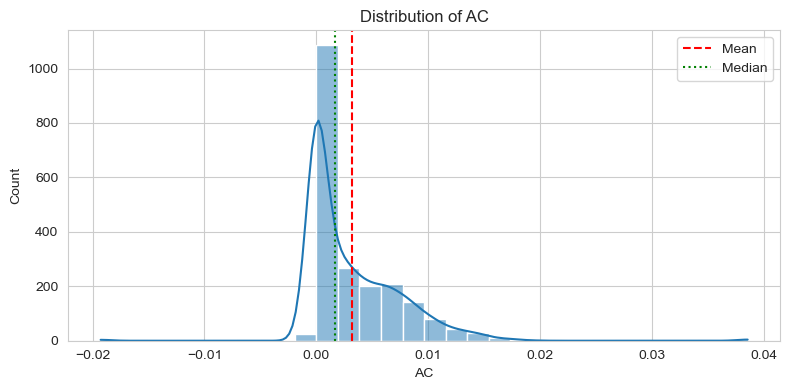

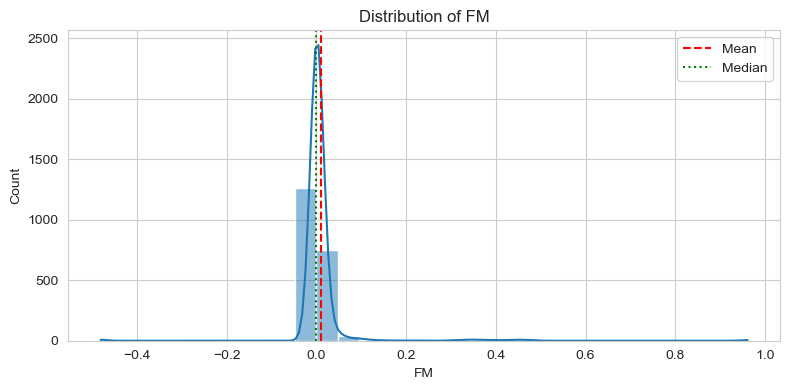

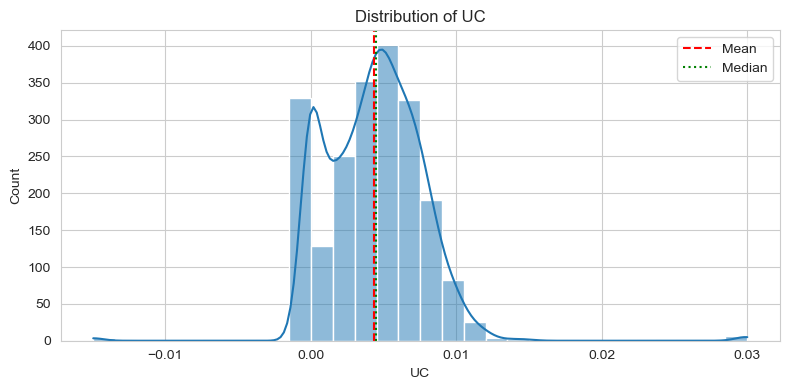

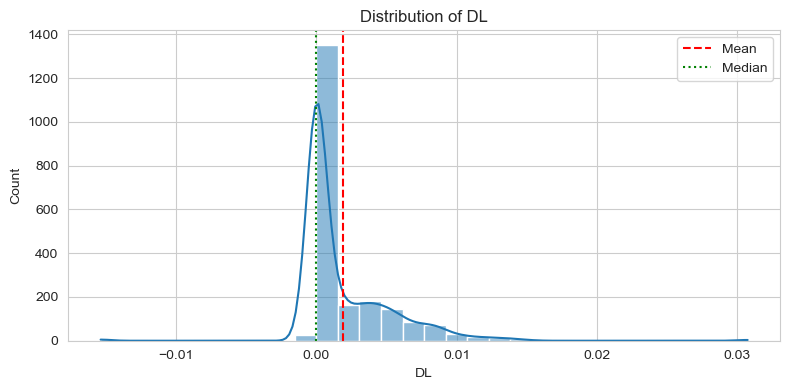

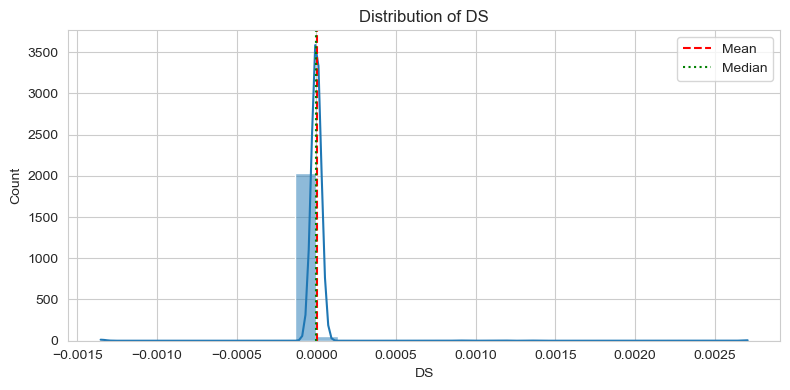

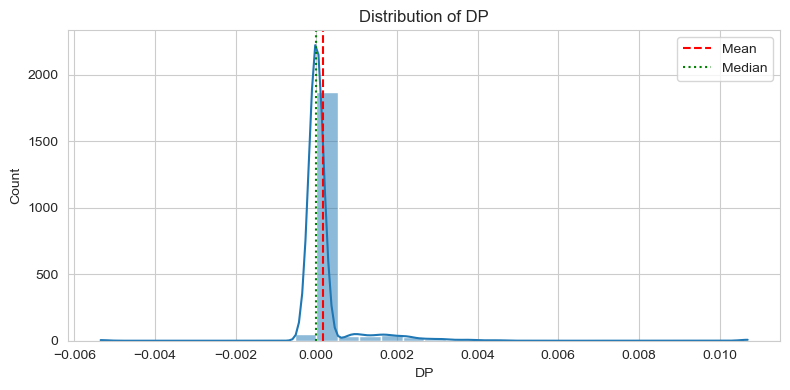

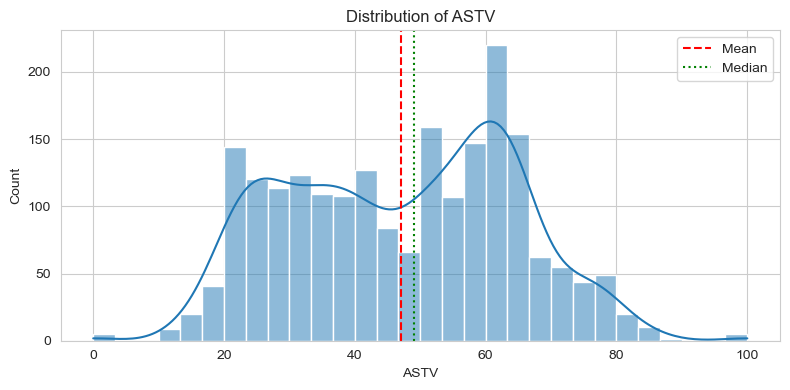

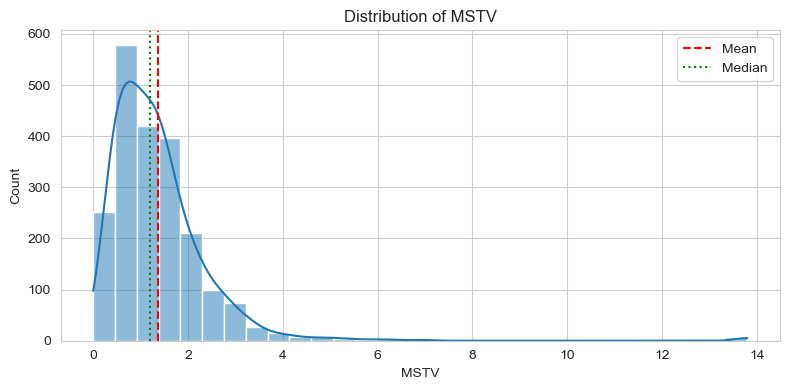

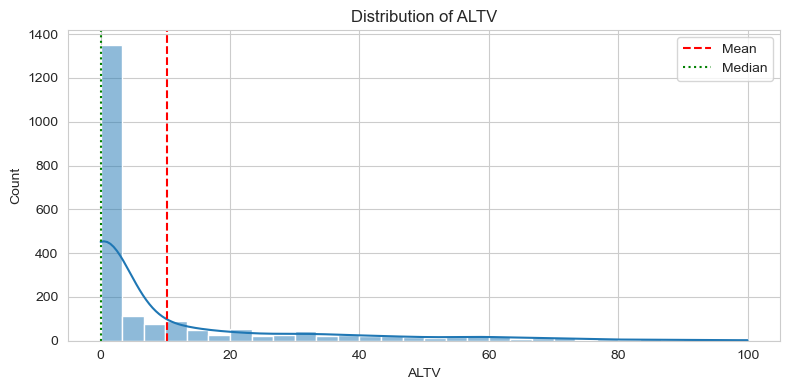

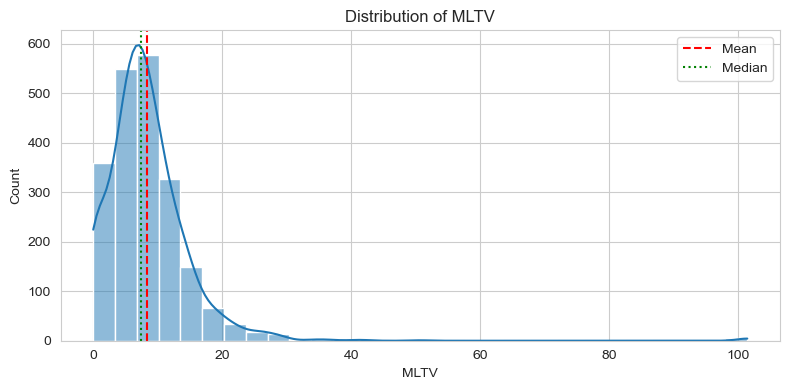

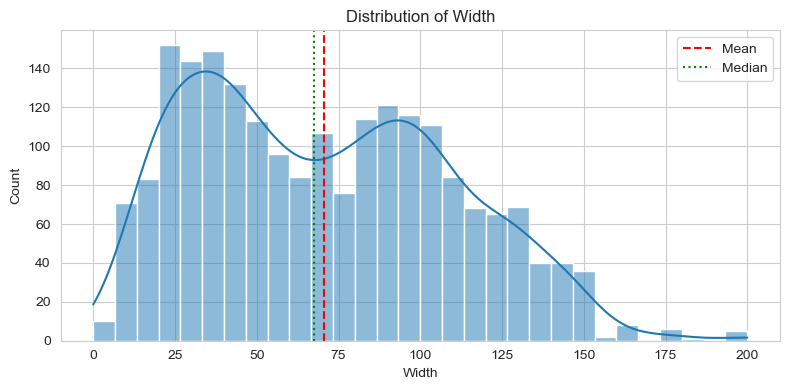

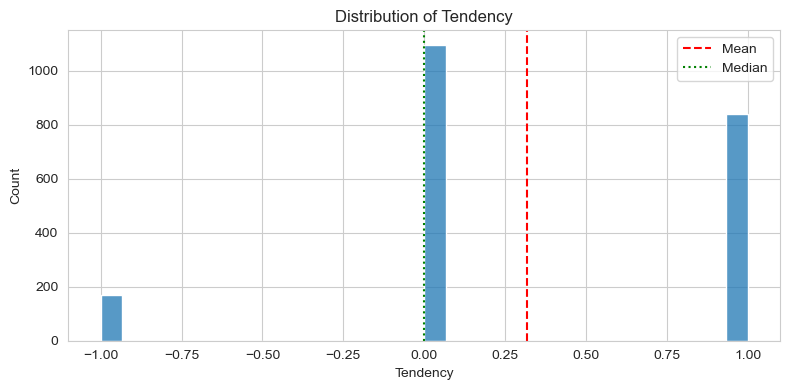

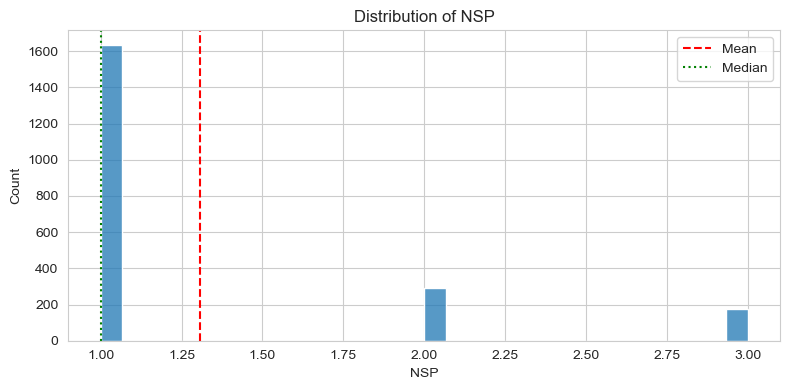

In [6]:
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=df[col].nunique() > 10,
        ax=ax
    )

    ax.axvline(
        df[col].mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )

    ax.axvline(
        df[col].median(),
        color="green",
        linestyle=":",
        label="Median"
    )

    ax.set_title(f"Distribution of {col}")
    ax.legend()
    plt.tight_layout()
    plt.show()


3.2 Box plots — outliers and IQR

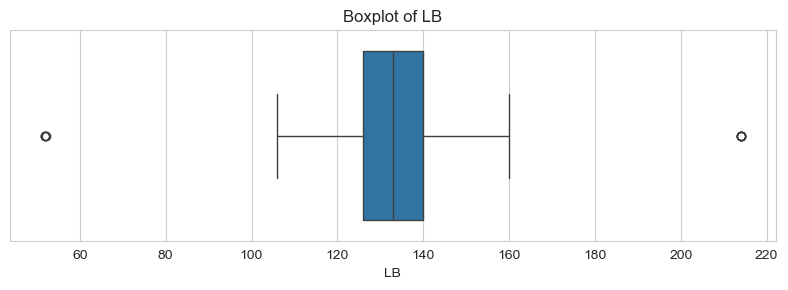

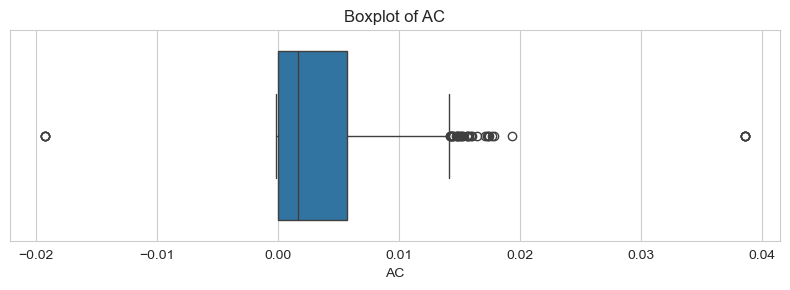

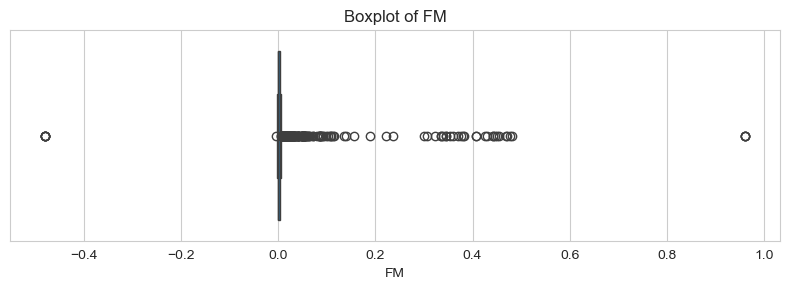

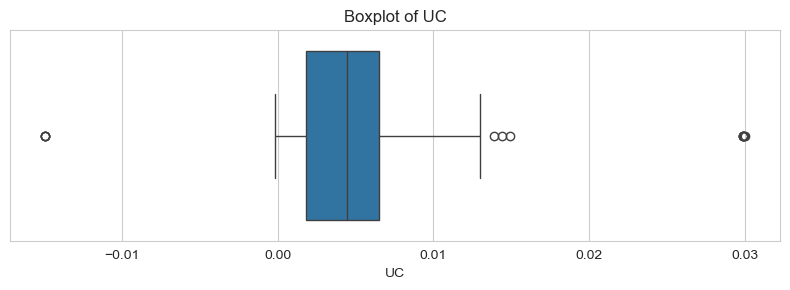

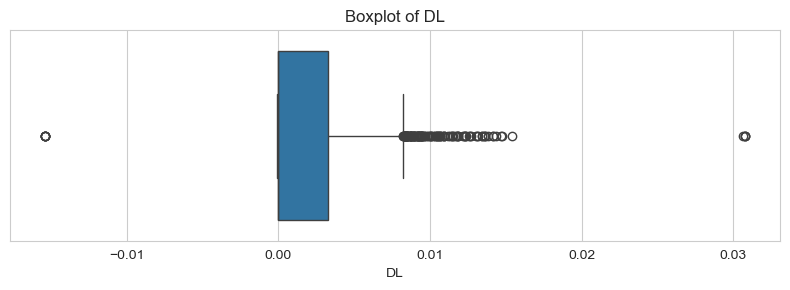

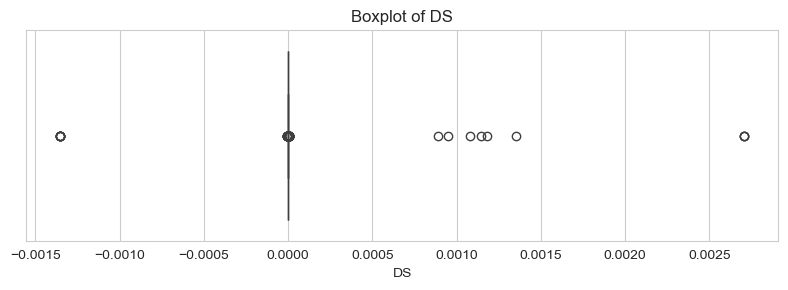

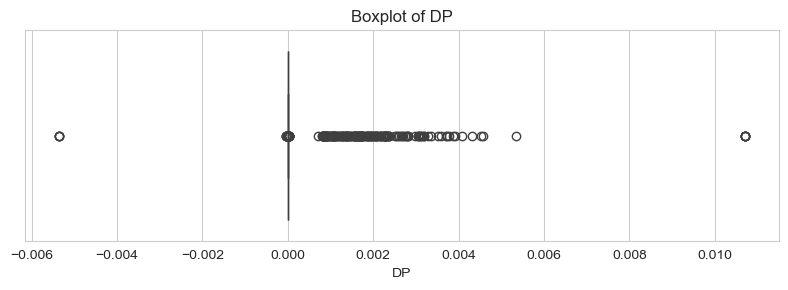

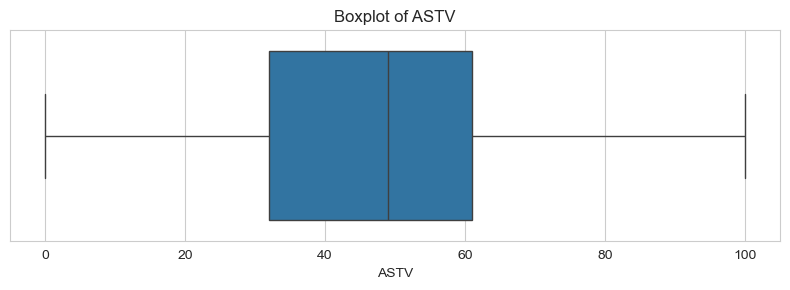

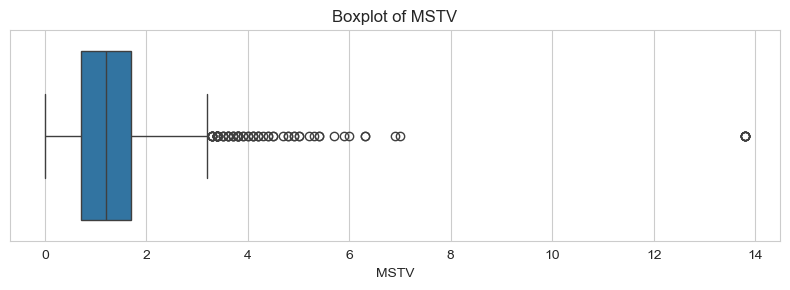

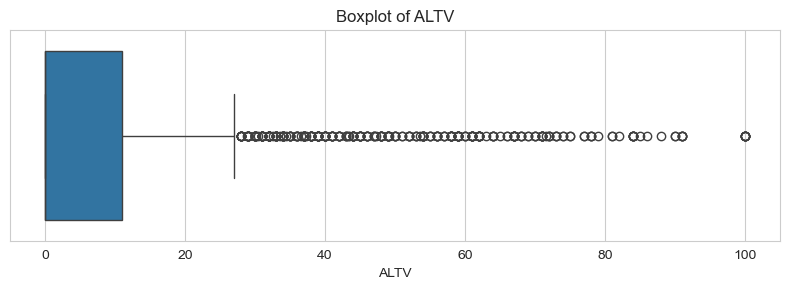

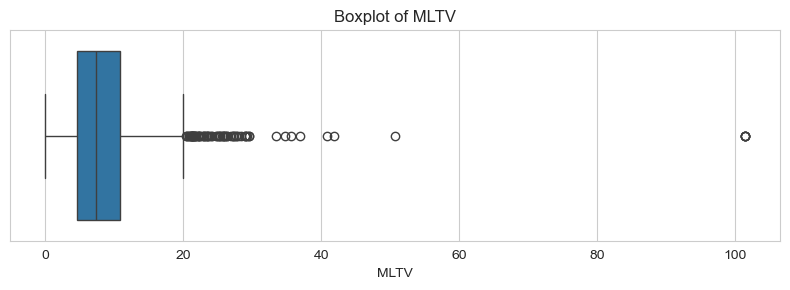

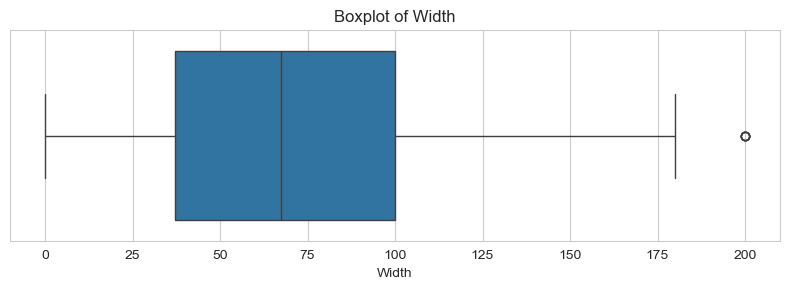

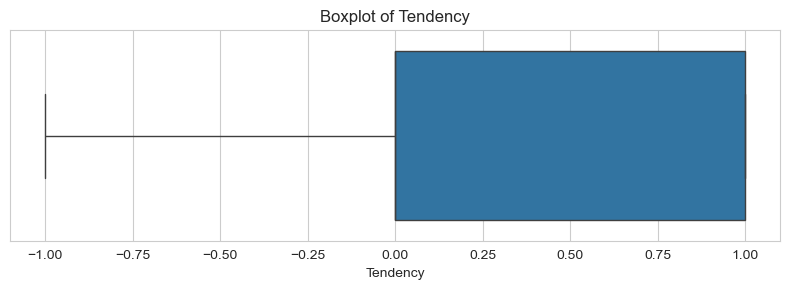

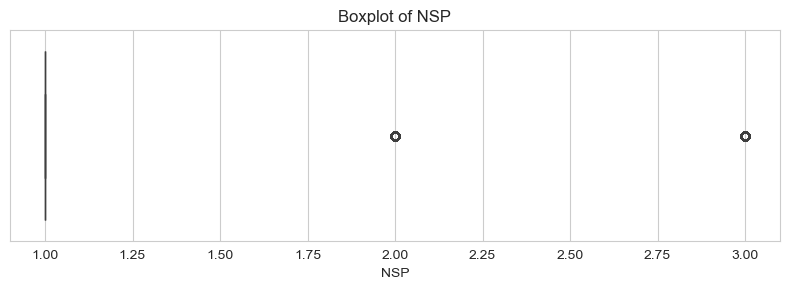

In [7]:
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=df, x=col)
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

In [8]:
# 7. OUTLIER DETECTION USING IQR
# ============================================================

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": count,
        "Outlier Percentage": count / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)
outlier_df = outlier_df.sort_values(
    "Outlier Count",
    ascending=False
)

print("\nOutlier report:")
print(outlier_df.round(3))

outlier_df.to_csv("cardiotocographic_outlier_report.csv", index=False)


Outlier report:
    Variable  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage
13       NSP        1.000        1.000            469              22.301
2         FM       -0.004        0.006            343              16.310
9       ALTV      -16.500       27.500            314              14.931
6         DP        0.000        0.000            284              13.505
4         DL       -0.005        0.008            124               5.896
5         DS        0.000        0.000            120               5.706
10      MLTV       -4.850       20.350             76               3.614
8       MSTV       -0.800        3.200             75               3.566
1         AC       -0.008        0.014             39               1.854
3         UC       -0.005        0.014             13               0.618
0         LB      105.000      161.000             10               0.476
11     Width      -57.500      194.500              5               0.238
7       ASTV      -11

3.3 Categorical frequencies


Frequency distribution of NSP:
NSP
1    1634
2     293
3     176
Name: count, dtype: int64


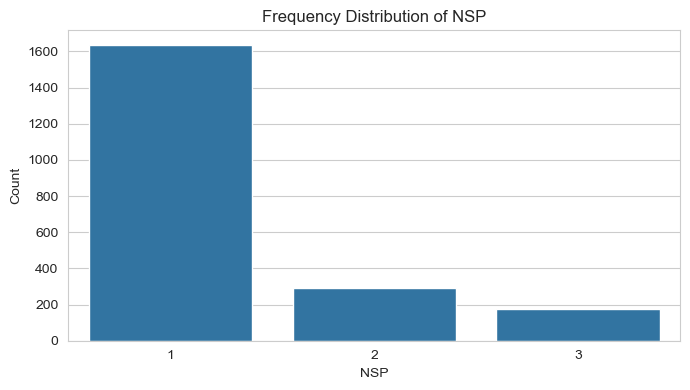


Frequency distribution of Tendency:
Tendency
-1     169
 0    1095
 1     839
Name: count, dtype: int64


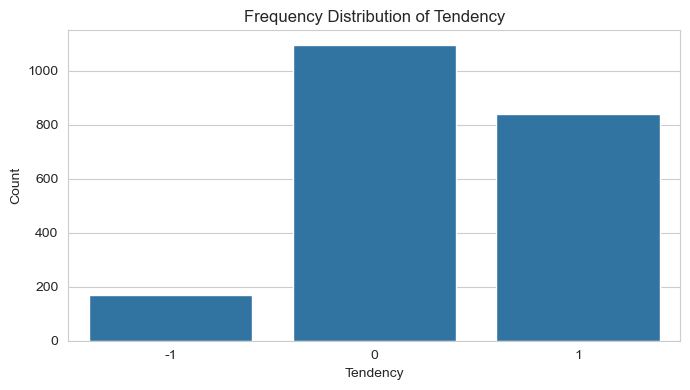

In [9]:
categorical_cols = [
    col for col in ["NSP", "Tendency"]
    if col in df.columns
]

for col in categorical_cols:
    print(f"\nFrequency distribution of {col}:")
    print(df[col].value_counts().sort_index())

    plt.figure(figsize=(7, 4))
    sns.countplot(
        data=df,
        x=col,
        order=sorted(df[col].dropna().unique())
    )
    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()


NSP CLASS


NSP class proportions:
NSP
1   0.777
2   0.139
3   0.084
Name: proportion, dtype: float64


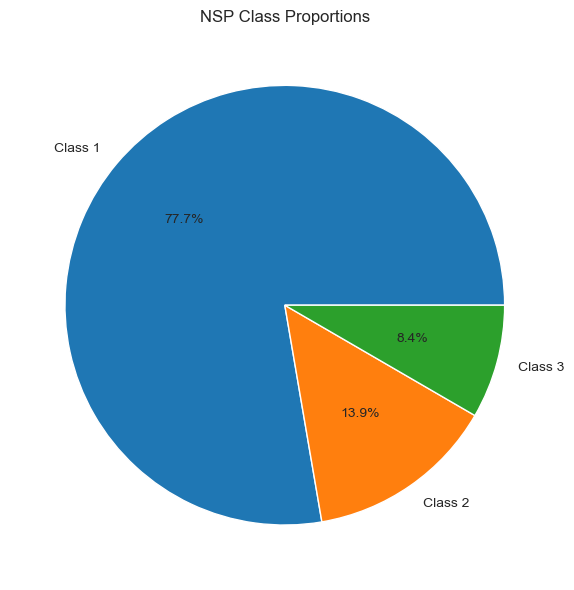

In [10]:
# NSP class proportions
if "NSP" in df.columns:
    print("\nNSP class proportions:")
    print(df["NSP"].value_counts(normalize=True).sort_index().round(3))

    plt.figure(figsize=(6, 6))
    df["NSP"].value_counts().sort_index().plot.pie(
        autopct="%1.1f%%",
        labels=[
            f"Class {i}"
            for i in df["NSP"].value_counts().sort_index().index
        ]
    )
    plt.title("NSP Class Proportions")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()


3.4 Correlation heatmap

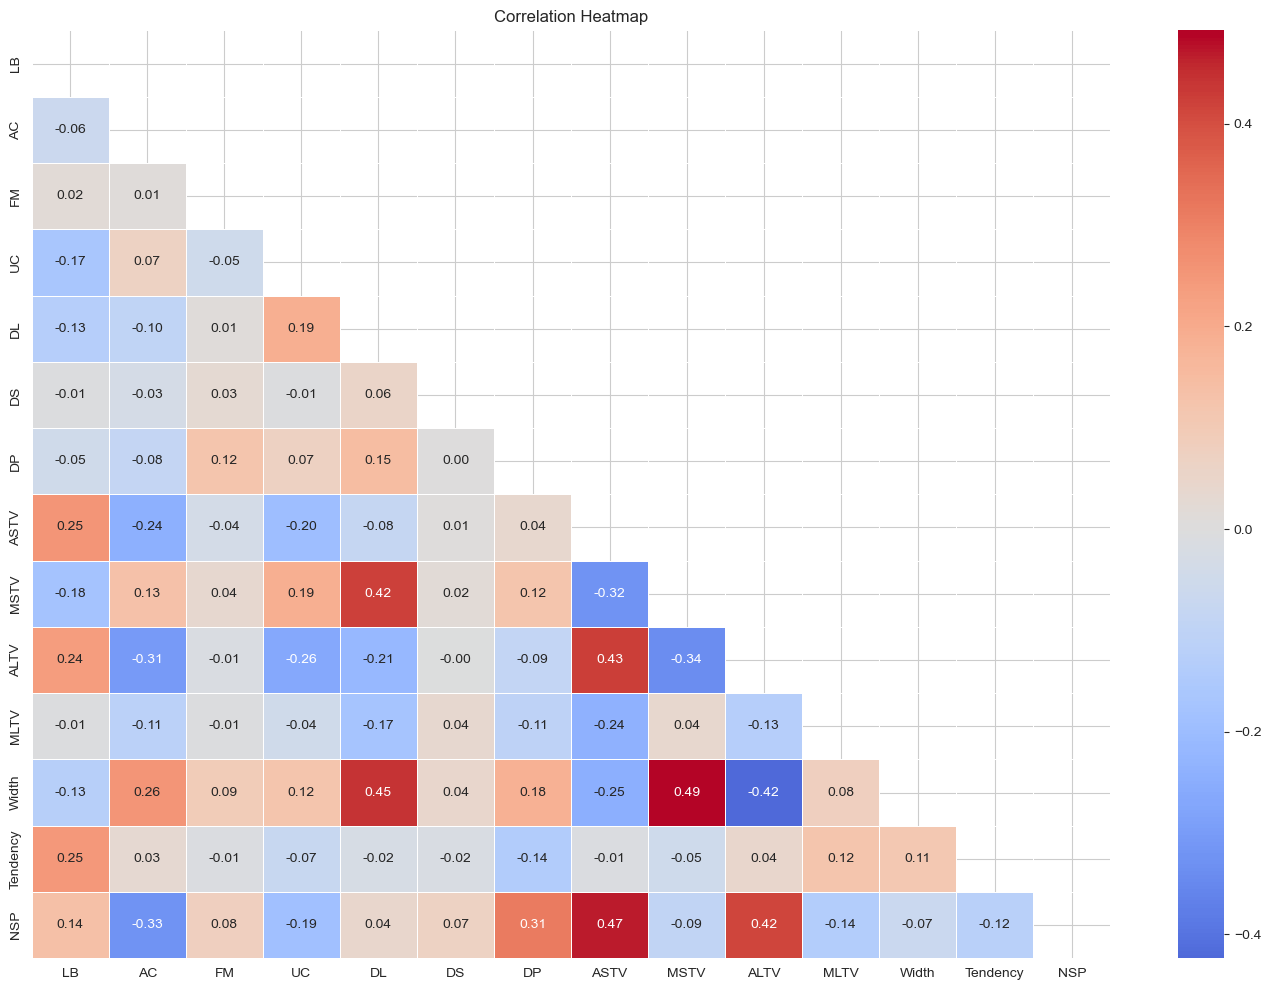

In [11]:
correlation = df[numeric_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(correlation, dtype=bool))

sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


Strongest correlations

In [12]:
correlation_pairs = (
    correlation.where(
        np.triu(np.ones(correlation.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("\nTop 10 strongest correlations:")
print(correlation_pairs.head(10))


Top 10 strongest correlations:
MSTV  Width    0.492
ASTV  NSP      0.467
DL    Width    0.446
ASTV  ALTV     0.427
ALTV  Width   -0.424
DL    MSTV     0.423
ALTV  NSP      0.416
MSTV  ALTV    -0.338
AC    NSP     -0.326
ASTV  MSTV    -0.322
dtype: float64


3.5 Advanced: violin plots, pair plots, target-wise comparison


Mean feature values by NSP class:
      ASTV   ALTV  MLTV  MSTV      LB  Width    AC    FM    UC    DL     DS  \
NSP                                                                           
1   42.430  5.359 8.796 1.470 131.976 73.483 0.004 0.007 0.005 0.002 -0.000   
2   61.947 29.228 8.365 0.732 141.850 49.328 0.000 0.018 0.002 0.001  0.000   
3   64.739 23.789 4.803 1.512 131.862 78.074 0.000 0.023 0.004 0.003  0.000   

       DP  
NSP        
1   0.000  
2   0.000  
3   0.001  

Median feature values by NSP class:
      ASTV   ALTV  MLTV  MSTV      LB  Width    AC    FM    UC    DL    DS  \
NSP                                                                          
1   41.000  0.000 7.950 1.300 132.000 71.000 0.003 0.000 0.005 0.000 0.000   
2   63.000 27.000 7.100 0.408 143.000 31.000 0.000 0.000 0.001 0.000 0.000   
3   65.000  0.000 3.400 1.600 132.000 90.500 0.000 0.001 0.003 0.002 0.000   

       DP  
NSP        
1   0.000  
2   0.000  
3   0.001  


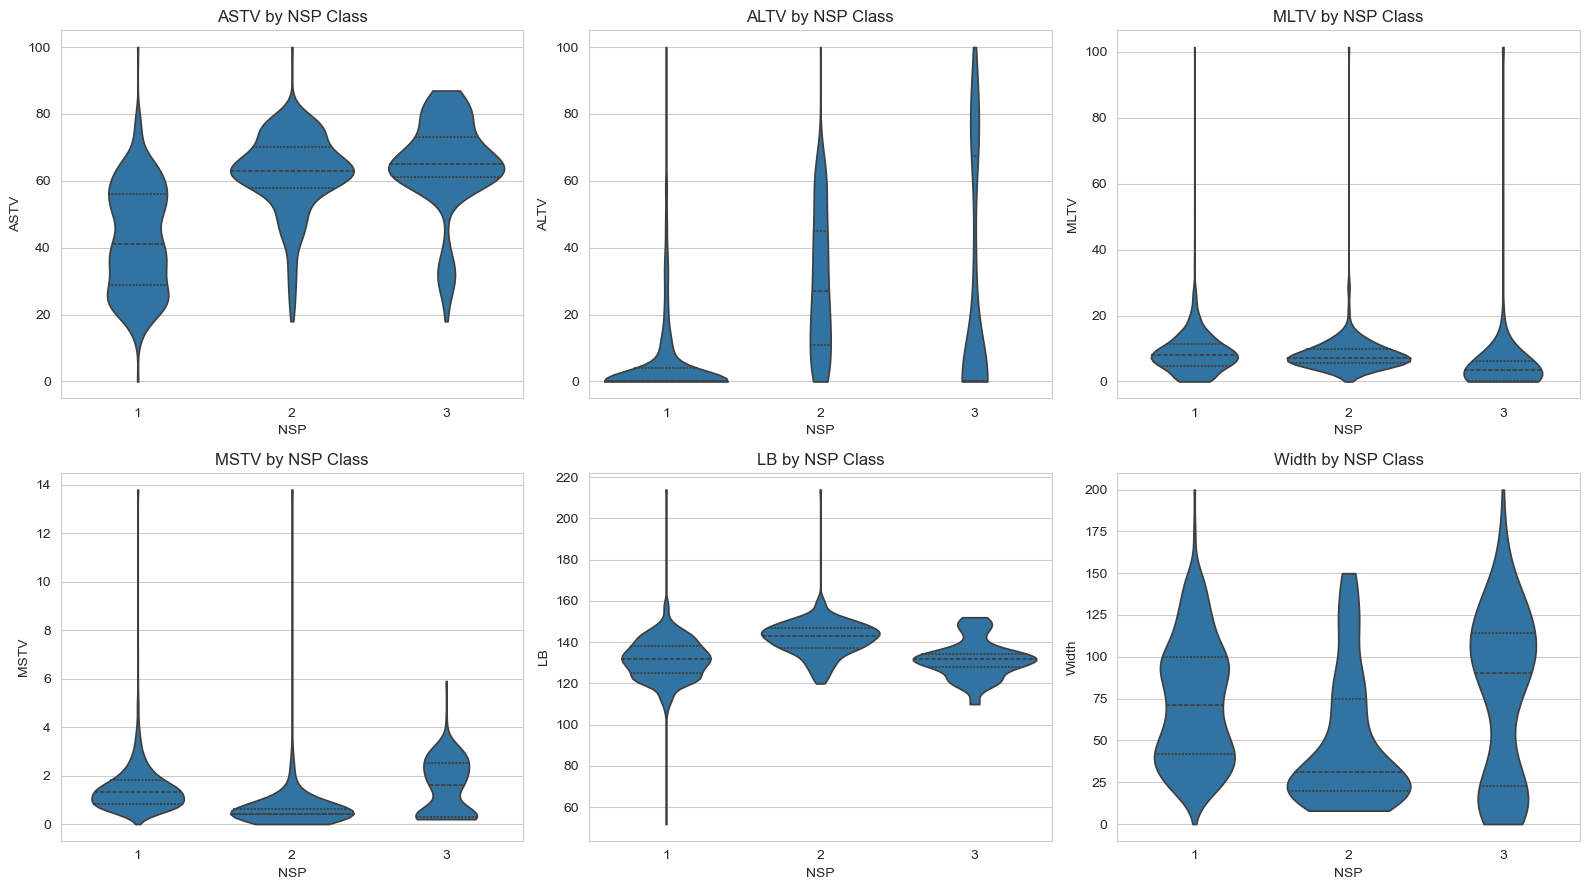

In [20]:
# ============================================================
# 10. TARGET-WISE STATISTICAL ANALYSIS
# ============================================================

if "NSP" in df.columns:

    target_features = [
        col for col in [
            "ASTV", "ALTV", "MLTV", "MSTV", "LB", "Width",
            "AC", "FM", "UC", "DL", "DS", "DP"
        ]
        if col in df.columns
    ]

    print("\nMean feature values by NSP class:")
    print(df.groupby("NSP")[target_features].mean().round(3))

    print("\nMedian feature values by NSP class:")
    print(df.groupby("NSP")[target_features].median().round(3))

    # Violin plots
    violin_features = [
        col for col in ["ASTV", "ALTV", "MLTV", "MSTV", "LB", "Width"]
        if col in df.columns
    ]

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    for ax, col in zip(axes.ravel(), violin_features):
        sns.violinplot(
            data=df,
            x="NSP",
            y=col,
            inner="quartile",
            cut=0,
            ax=ax
        )

        ax.set_title(f"{col} by NSP Class")

    for ax in axes.ravel()[len(violin_features):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("NSP column not found in the dataset.")

PAIR PLOT

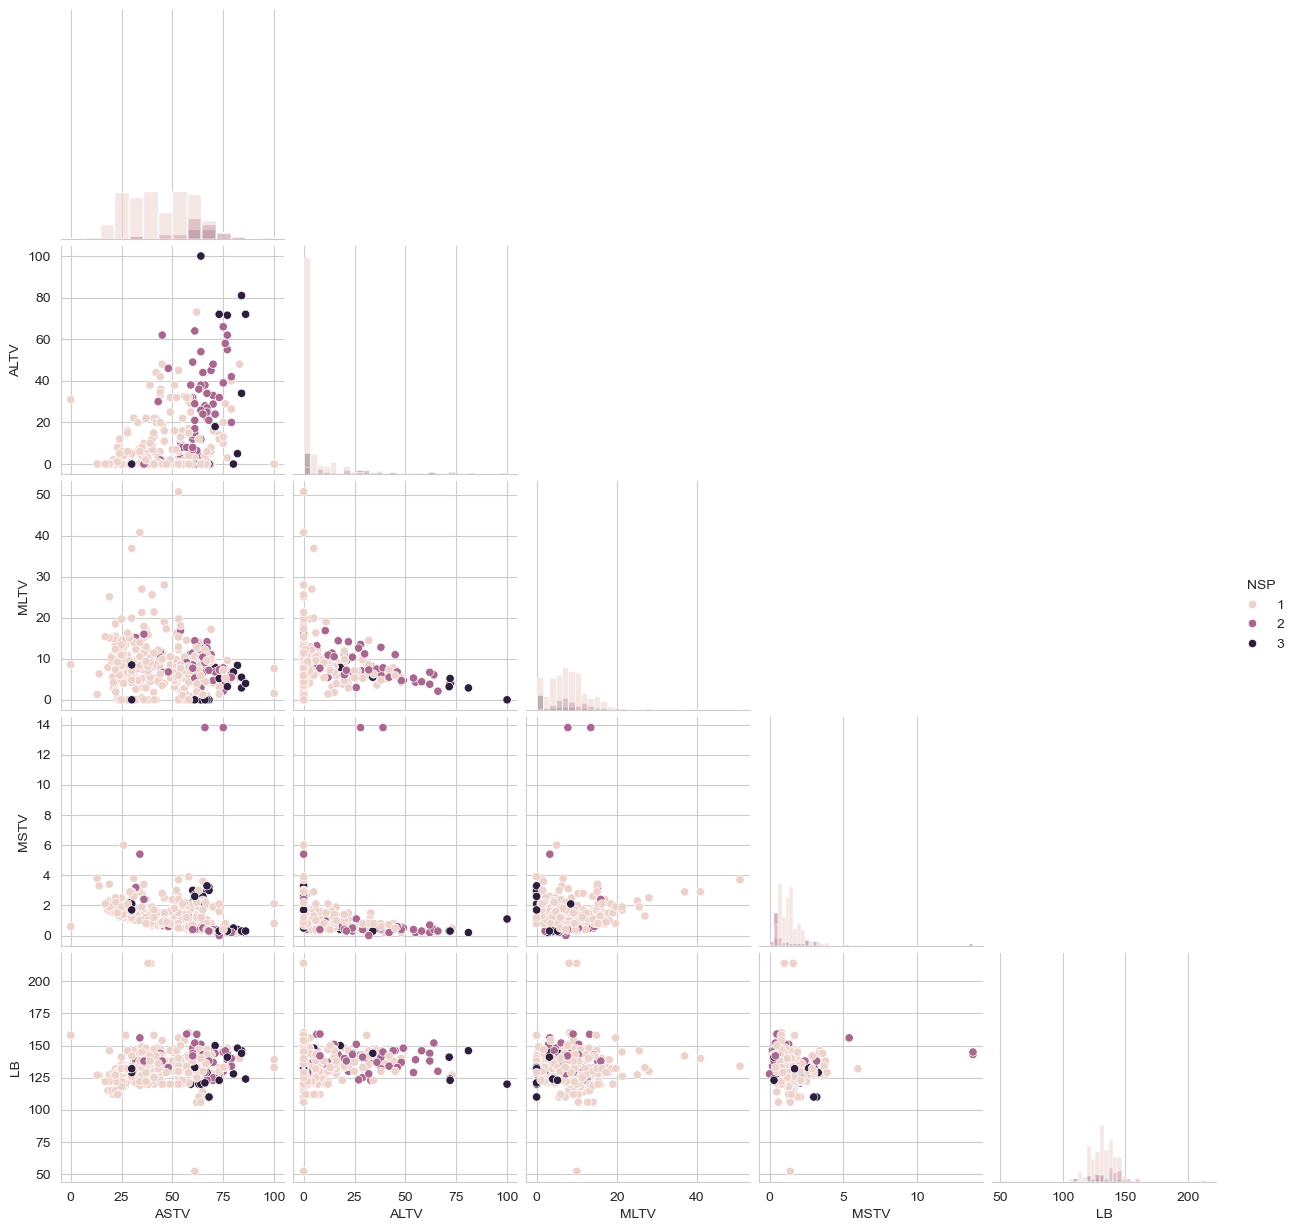

In [21]:
pair_features = [
    col for col in ["ASTV", "ALTV", "MLTV", "MSTV", "LB"]
    if col in df.columns
]

if len(pair_features) >= 2:
    sample_size = min(400, len(df))
    sample_df = df.sample(
        n=sample_size,
        random_state=42
    )

    if "NSP" in sample_df.columns:
        sns.pairplot(
            sample_df,
            vars=pair_features,
            hue="NSP",
            corner=True,
            diag_kind="hist"
        )
    else:
        sns.pairplot(
            sample_df,
            vars=pair_features,
            corner=True,
            diag_kind="hist"
        )

    plt.show()

SCATTER PLOTS

In [ ]:
scatter_pairs = [
    ("ASTV", "MLTV"),
    ("ASTV", "ALTV"),
    ("LB", "ASTV"),
    ("MSTV", "MLTV"),
    ("Width", "ASTV")
]

for x_col, y_col in scatter_pairs:
    if x_col in df.columns and y_col in df.columns:
        plt.figure(figsize=(7, 5))

        if "NSP" in df.columns:
            sns.scatterplot(
                data=df,
                x=x_col,
                y=y_col,
                hue="NSP",
                alpha=0.7
            )
        else:
            sns.scatterplot(
                data=df,
                x=x_col,
                y=y_col,
                alpha=0.7
            )

        plt.title(f"{x_col} vs {y_col}")
        plt.tight_layout()
        plt.show()


PAIR PLOT

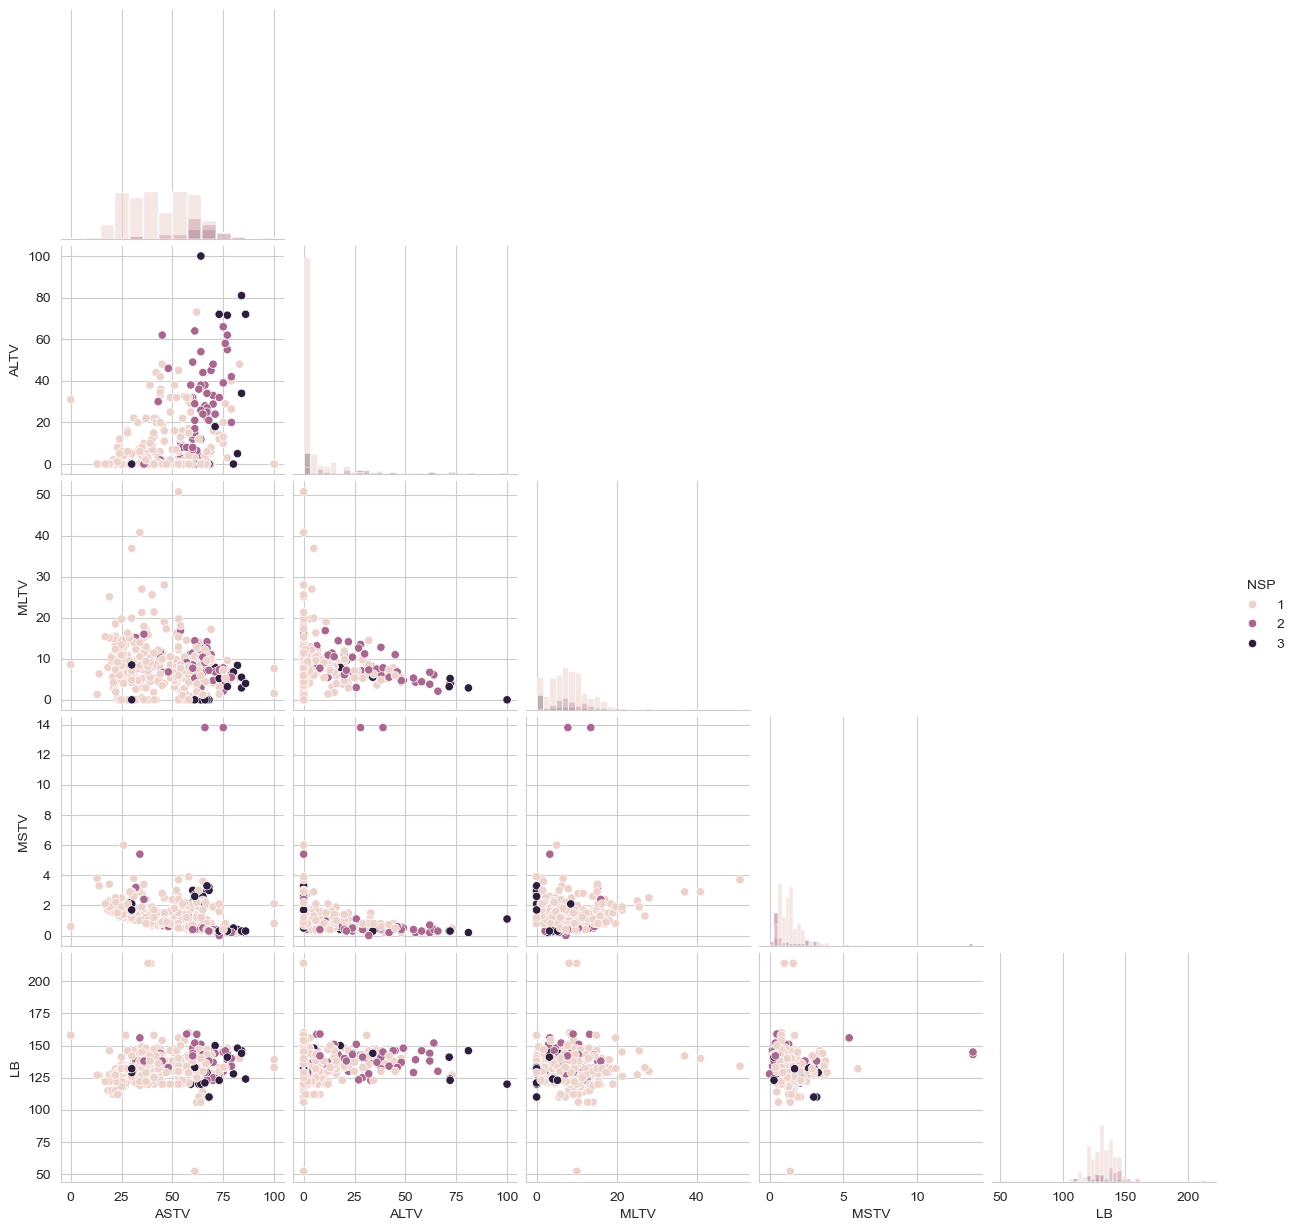

In [22]:
pair_features = [
    col for col in ["ASTV", "ALTV", "MLTV", "MSTV", "LB"]
    if col in df.columns
]

if len(pair_features) >= 2:
    sample_size = min(400, len(df))
    sample_df = df.sample(
        n=sample_size,
        random_state=42
    )

    if "NSP" in sample_df.columns:
        sns.pairplot(
            sample_df,
            vars=pair_features,
            hue="NSP",
            corner=True,
            diag_kind="hist"
        )
    else:
        sns.pairplot(
            sample_df,
            vars=pair_features,
            corner=True,
            diag_kind="hist"
        )

    plt.show()


4. Pattern Recognition and Insights

4.1 The three-variable pathological signature

In [23]:
df.groupby("NSP")[["ASTV","ALTV","MLTV","MSTV","LB","Width"]].mean().round(2)

,ASTV,ALTV,MLTV,MSTV,LB,Width
NSP,,,,,,
1,42.430,5.360,8.800,1.470,131.980,73.480
2,61.950,29.230,8.370,0.730,141.850,49.330
3,64.740,23.790,4.800,1.510,131.860,78.070


4.2 Feature ranking for downstream work

In [24]:
corr_target = df[num_cols].corr()["NSP"].drop("NSP").sort_values(key=abs, ascending=False)
print(corr_target)


ASTV        0.467
ALTV        0.416
AC         -0.326
DP          0.313
UC         -0.190
MLTV       -0.136
LB          0.135
Tendency   -0.122
MSTV       -0.093
FM          0.079
Width      -0.069
DS          0.068
DL          0.043
Name: NSP, dtype: float64


4.4 Class-imbalance structure

In [25]:
print(df["NSP"].value_counts(normalize=True).round(3))
# 1    0.780
# 2    0.140
# 3    0.080

NSP
1   0.777
2   0.139
3   0.084
Name: proportion, dtype: float64


 FINAL DATA QUALITY CHECK

In [26]:
print("\nFinal dataset shape:", df.shape)

print("\nFinal data types:")
print(df.dtypes)

print("\nFinal missing values:")
print(df.isnull().sum())

print("\nFinal descriptive statistics:")
print(df.describe().T)


Final dataset shape: (2103, 14)

Final data types:
LB          float64
AC          float64
FM          float64
UC          float64
DL          float64
DS          float64
DP          float64
ASTV        float64
MSTV        float64
ALTV        float64
MLTV        float64
Width       float64
Tendency      int32
NSP           int32
dtype: object

Final missing values:
LB          0
AC          0
FM          0
UC          0
DL          0
DS          0
DP          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
Width       0
Tendency    0
NSP         0
dtype: int64

Final descriptive statistics:
             count    mean    std    min     25%     50%     75%     max
LB       2,103.000 133.342 11.268 51.842 126.000 133.000 140.000 214.000
AC       2,103.000   0.003  0.004 -0.019   0.000   0.002   0.006   0.039
FM       2,103.000   0.010  0.068 -0.481   0.000   0.000   0.003   0.961
UC       2,103.000   0.004  0.003 -0.015   0.002   0.004   0.007   0.030
DL       2,103.000   0.002

ALL OUTPUTS

In [27]:

df.to_csv("cardiotocographic_cleaned.csv", index=False)
df_log.to_csv("cardiotocographic_log_transformed.csv", index=False)

print("\nEDA completed successfully.")
print("Saved: cardiotocographic_cleaned.csv")
print("Saved: cardiotocographic_log_transformed.csv")
print("Saved: cardiotocographic_statistical_summary.csv")
print("Saved: cardiotocographic_outlier_report.csv")


EDA completed successfully.
Saved: cardiotocographic_cleaned.csv
Saved: cardiotocographic_log_transformed.csv
Saved: cardiotocographic_statistical_summary.csv
Saved: cardiotocographic_outlier_report.csv
